# Riproduzione (Parti A–C, senza GPU) su Google Colab — *You Don't Bring Me Flowers* (RecSys 2025, Best Full Paper)

Versione ridotta del notebook di riproduzione: **solo Parti A, B, C, tutte eseguibili su CPU**, nessuna cella di training.

| Parte | Cosa fa |
|---|---|
| **A** | Setup: cartelle di output, clone del repo al commit fissato (usato così com'è), dipendenze, controlli |
| **B** | Rigenera le figure del paper dai CSV *pubblicati* dagli autori |
| **C** | Rigenera gli split e **riesegue l'intera valutazione conformal** (script `experiments/*.sh`, 16 comandi × 10 run) sui punteggi pre-calcolati degli autori; confronto numerico con i loro CSV |

**Cosa ti aspetti alla fine:** nella tabella di C3, 16 file `IDENTICO` (al massimo `QUASI IDENTICO`, differenze < 1e-4) e 2 `NON RIGENERATO` (i due CSV di β=0.1 e β=1.5 non sono prodotti dagli script ufficiali). Ogni comando di C2 stampa quanto ci mette: **è l'informazione che serve per decidere dove far girare il resto**.

**Attenzione al numero di worker (osservazione 9):** per il metodo `hybrid` i numeri dipendono dal numero di processi worker di `ranker_kuairand.py`. Gli script ufficiali usano `--cores 8`; il codice però usa `min(--cores, os.cpu_count())`, quindi su una macchina con 2 CPU userebbe 2 worker e darebbe numeri **diversi** (stessa distribuzione, estrazioni casuali diverse). Questo notebook lancia il ranker tramite un piccolo wrapper che impone 8 worker anche con 2 CPU (più lento, stesso risultato degli autori). I CSV già presenti su Drive, prodotti con un numero diverso di worker, vengono **saltati** dalla ripresa: la cella C3 mostra dove e di quanto differiscono e la cella C5 verifica il caso `hybrid` in pochi minuti.

**Dopo ogni riavvio del runtime rieseguire dall'inizio** (le variabili vanno perse, i file salvati no). Le celle controllano le variabili e lo dicono chiaramente se mancano.

**Scarto dal protocollo** (solo quelli che toccano A–C): `usetex` disattivato nei 3 script di plotting (non c'è LaTeX; cambia solo il font); `pandas<3` (gli script usano `include_groups=True`); installata `torchsparsegradutils` (importata da `SIGformer/model.py` ma assente dal `requirement.txt` degli autori); `PYTHONPATH=.` anche per i plot; `ranker_kuairand.py` viene lanciato tramite il wrapper `_ranker_workers.py` (non modifica il codice degli autori) che fa valere 8 il numero di worker anche con meno CPU, come nel protocollo originale (`--cores 8`): è necessario per riprodurre esattamente il metodo `hybrid` (osservazione 9); PyTorch preinstallato invece del 2.5.0 pinnato (A–C non usano la GPU).

## Parte A — Setup

In [4]:
import os, sys, subprocess, shutil, time, re, glob, json, textwrap
from pathlib import Path

NB_START = time.time()          # per il budget di tempo della Parte D
WORK = Path("/content")
OUT_DIR = "/content/drive/MyDrive/IR_RecSys2025_repro"   # output persistente su Google Drive

def _detect_gpu():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True, timeout=30).returncode == 0
    except Exception:
        return False
def _gpu_ids():
    try:
        out = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True, timeout=30).stdout
        n = sum(1 for l in out.splitlines() if l.startswith("GPU "))
    except Exception:
        n = 0
    return list(range(n)) if n else [0]
HAS_GPU = _detect_gpu()
GPU_IDS = _gpu_ids() if HAS_GPU else [0]    # con 2 GPU la Parte D lancia 2 run in parallelo (una per GPU)
print("GPU rilevata:", HAS_GPU, "| n. GPU:", len(GPU_IDS) if HAS_GPU else 0, "-> modalita'", "GPU" if HAS_GPU else "CPU (le Parti A-C funzionano uguale; la Parte D e' limitata, vedi note sopra)")

# ===== CONFIGURAZIONE (modifica solo se sai perche') =====
PAPER_COMMIT   = "f4dfa8a727d560cd6c7c0d99a981bff690ee6b7a"   # commit del repo ispezionato e usato per questo notebook
REPO_URL       = "https://github.com/geektoni/mitigating-harm-recsys.git"


EPOCHS, RUNS   = 100, 10        # protocollo ufficiale
CORES          = 8   # processi worker di ranker_kuairand.py = --cores degli script ufficiali. NON ridurre: per 'hybrid' i risultati dipendono da questo numero (osservazione 9); con meno CPU gira piu' lento ma da' lo stesso risultato

# Batch size: il README e methods/run_all.sh NON coincidono (vedi nota in Parte D). Default = run_all.sh.
BATCH_PROFILE  = "run_all"      # "run_all" | "readme"
INCLUDE_NCFHARM = True          # ncfharm e' in run_all.sh ma NON e' usato da experiments/*.sh

PER_RUN_RESUME = True           # vedi punto 7 dell'elenco scarti; False = comando degli autori esatto (--runs 10)
RUN_TRAINING   = None           # None = automatico (True con GPU, False su CPU); metti True per forzare il training anche su CPU (solo ncf, molto lento)
REUSE_AUTHORS_FOR_MISSING = True  # Parte D: per i modelli non riaddestrati usa i pickle degli autori (valutazione ibrida)
KEEP_INTERMEDIATE_CKPT = False  # i pickle a epoca 10,20,...,90 non servono alla valutazione (gli autori rilasciano solo l'epoca 100)
TOTAL_BUDGET_HOURS = 11.0       # durata massima del notebook (ore); il training si ferma in tempo per lasciare spazio alla valutazione finale
EVAL_RESERVE_DEFAULT_HOURS = 1.5  # riserva per la valutazione finale se la durata della Parte C non e' stata misurata
EXTRA_PYG_EXTENSIONS = False    # torch_scatter/sparse/cluster/pyg_lib: il codice degli autori NON li importa direttamente; True solo se compare un ImportError

GPU rilevata: False | n. GPU: 0 -> modalita' CPU (le Parti A-C funzionano uguale; la Parte D e' limitata, vedi note sopra)


In [5]:
assert all(n in globals() for n in ('HAS_GPU', 'CORES', 'WORK')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
def sh(cmd, check=True, tail=2500, cwd=None, env=None):
    print("$", cmd)
    p = subprocess.run(cmd, shell=True, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, cwd=cwd, env=env)
    out = p.stdout or ""
    print(out if len(out) <= tail else "...\n" + out[-tail:])
    if check and p.returncode != 0:
        raise RuntimeError(f"Comando fallito (exit {p.returncode}): {cmd}")
    return out

print("Python:", sys.version.split()[0], "| CPU:", os.cpu_count())
if HAS_GPU:
    sh("nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader", check=False)
sh(f"free -g | head -2; df -h {WORK} | tail -1", check=False)

Python: 3.13.16 | CPU: 2
$ free -g | head -2; df -h /content | tail -1
               total        used        free      shared  buff/cache   available
Mem:              12           1           8           0           3          11
overlay         108G   21G   88G  20% /



'               total        used        free      shared  buff/cache   available\nMem:              12           1           8           0           3          11\noverlay         108G   21G   88G  20% /\n'

In [6]:
assert all(n in globals() for n in ('sh', 'OUT_DIR')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
from google.colab import drive
drive.mount("/content/drive")

D = Path(OUT_DIR)
DIRS = {k: D / k for k in [
    "retrain_pickles",        # pickle riaddestrati (equivalente di methods/kuairand/results)
    "eval_on_authors",        # CSV rigenerati da valutazione su pickle degli autori (Parte C)
    "eval_on_retrained",      # CSV da valutazione su pickle riaddestrati / ibridi (Parte D)
    "figures_authors_csv",    # figure dai CSV degli autori (Parte B)
    "figures_eval_on_authors",
    "figures_retrained",
    "logs", "patches"]}
for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)
print("Cartella di lavoro su Drive:", D)

Mounted at /content/drive
Cartella di lavoro su Drive: /content/drive/MyDrive/IR_RecSys2025_repro


In [7]:
assert all(n in globals() for n in ('sh', 'DIRS', 'WORK', 'REPO_URL')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
REPO_AUTHORS = WORK / "repo_authors"     # copia INTATTA del repo (con i pickle pre-calcolati degli autori)
REPO_RETRAIN = WORK / "repo_retrain"     # copia per il riaddestramento (Parte D)
REPO_EVAL    = WORK / "repo_eval"        # copia per la valutazione ibrida/riaddestrata (Parte D)

if not REPO_AUTHORS.exists():
    sh(f"git clone -q {REPO_URL} {REPO_AUTHORS}")
sh(f"git -C {REPO_AUTHORS} checkout -q {PAPER_COMMIT} && git -C {REPO_AUTHORS} log -1 --format='%H %ci %s'")
sh(f"ls {REPO_AUTHORS}/KuaiRand-Harm/training/ && du -sh {REPO_AUTHORS}/methods/kuairand/results {REPO_AUTHORS}/results")
n_pk = len(glob.glob(str(REPO_AUTHORS / "methods/kuairand/results/*.zlib.pickle")))
print("Pickle pre-calcolati degli autori trovati:", n_pk, "(attesi 60 = 6 modelli x 10 run)")
assert n_pk == 60, "Il repo non contiene i 60 pickle attesi: controlla il commit"

$ git clone -q https://github.com/geektoni/mitigating-harm-recsys.git /content/repo_authors

$ git -C /content/repo_authors checkout -q f4dfa8a727d560cd6c7c0d99a981bff690ee6b7a && git -C /content/repo_authors log -1 --format='%H %ci %s'
f4dfa8a727d560cd6c7c0d99a981bff690ee6b7a 2026-06-11 16:28:13 +0200 Create LICENSE

$ ls /content/repo_authors/KuaiRand-Harm/training/ && du -sh /content/repo_authors/methods/kuairand/results /content/repo_authors/results
single_and_repeated_interactions_is_click.csv.gzip
464M	/content/repo_authors/methods/kuairand/results
904K	/content/repo_authors/results

Pickle pre-calcolati degli autori trovati: 60 (attesi 60 = 6 modelli x 10 run)


In [8]:
assert all(n in globals() for n in ('sh', 'HAS_GPU', 'REPO_AUTHORS', 'WORK')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
# ---- Dipendenze ----
# Il requirements.txt degli autori pinna torch 2.5.0+cu124 (wheel esistono solo fino a Python 3.12 e servono una GPU).
# Con GPU questa build funziona anche su P100 (Pascal), che i PyTorch compilati con CUDA >= 12.8 non supportano.
PINNED_TORCH = False and HAS_GPU and sys.version_info < (3, 13)
if PINNED_TORCH:
    sh("pip install -q torch==2.5.0 torchvision==0.20.0 torchaudio==2.5.0 --index-url https://download.pytorch.org/whl/cu124", tail=1500)
elif not HAS_GPU:
    print("Modalita' CPU: uso il PyTorch preinstallato (scarto dichiarato n.6).")
else:
    print("Python >= 3.13: wheel torch 2.5.0 non disponibili -> uso il torch preinstallato (scarto dichiarato n.6).")

sh('pip install -q "pandas>=2.2,<3" scipy scikit-learn matplotlib seaborn tqdm networkx torch_geometric', tail=1500)

# Dipendenza NON elencata nel requirement.txt degli autori ma importata da methods/SIGformer/model.py
sh("pip install -q torchsparsegradutils", check=False, tail=800)
if subprocess.run([sys.executable, "-c", "import torchsparsegradutils"], capture_output=True).returncode != 0:
    print("pip non ha trovato torchsparsegradutils: provo dal repository GitHub")
    sh("pip install -q git+https://github.com/cai4cai/torchsparsegradutils.git", tail=1500)

if EXTRA_PYG_EXTENSIONS:
    ver = subprocess.check_output([sys.executable, "-c", "import torch;print(torch.__version__.split('+')[0], 'cu'+torch.version.cuda.replace('.',''))"], text=True).split()
    sh(f"pip install -q pyg_lib torch_scatter torch_sparse torch_cluster torch_spline_conv -f https://data.pyg.org/whl/torch-{ver[0]}+{ver[1]}.html", tail=1500)

CHECK = WORK / "_check_env.py"
CHECK.write_text("""
import os, sys, torch, pandas, numpy, sklearn, scipy, torch_geometric, torchsparsegradutils
print('torch', torch.__version__, '| cuda build', torch.version.cuda, '| cuda disponibile:', torch.cuda.is_available())
print('pandas', pandas.__version__, '| numpy', numpy.__version__, '| sklearn', sklearn.__version__, '| torch_geometric', torch_geometric.__version__)
assert int(pandas.__version__.split('.')[0]) < 3, 'pandas>=3 non e compatibile con gli script degli autori'
if os.environ.get('NO_GPU') != '1':
    assert torch.cuda.is_available(), 'GPU non visibile a PyTorch: controlla Accelerator nelle impostazioni del notebook'
    try:
        for i in range(torch.cuda.device_count()):
            x = torch.randn(64, 64, device='cuda:%d' % i); float((x @ x).sum().item())
            print('GPU', i, torch.cuda.get_device_name(i), '| capability', torch.cuda.get_device_capability(i), '| test di calcolo OK')
    except Exception as e:
        print('TEST DI CALCOLO SU GPU FALLITO:', e); sys.exit(3)
else:
    print('Modalita CPU')
sys.path.insert(0, '__REPO__/methods')
from LightGCL.model import LightGCL
from SIGformer.model import SIGformer
from GFormer.model import GFormer, GTLayer
from SiReN.model import SiReN
from NCF.model import RankerNN
print('Import di tutti i modelli: OK')
""".replace("__REPO__", str(REPO_AUTHORS)))

def run_check():
    r = subprocess.run(f"NO_GPU={0 if (HAS_GPU and False) else 1} {sys.executable} {CHECK}", shell=True, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print(r.stdout[-3000:]); return r.returncode
rc = run_check()
if rc == 3 and HAS_GPU and False:
    print("La GPU non esegue i kernel di questo PyTorch (tipico: P100 + PyTorch compilato con CUDA >= 12.8). Provo la build cu126.")
    sh("pip install -q --upgrade torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126", tail=1500)
    rc = run_check()
if rc != 0:
    raise RuntimeError("Controllo dell'ambiente fallito: leggi l'output sopra. Se e' una P100, scegli 'GPU T4 x2' nelle impostazioni.")

Modalita' CPU: uso il PyTorch preinstallato (scarto dichiarato n.6).
$ pip install -q "pandas>=2.2,<3" scipy scikit-learn matplotlib seaborn tqdm networkx torch_geometric
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 31.5 MB/s eta 0:00:00

$ pip install -q torchsparsegradutils
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.6/231.6 kB 6.3 MB/s eta 0:00:00

torch 2.11.0+cpu | cuda build None | cuda disponibile: False
pandas 2.2.3 | numpy 2.1.3 | sklearn 1.6.1 | torch_geometric 2.8.1
Modalita CPU
Import di tutti i modelli: OK



In [9]:
assert all(n in globals() for n in ('sh', 'DIRS', 'REPO_AUTHORS', 'REPO_RETRAIN')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
# ---- Patch documentate (ognuna con assert: se il repo cambia, il notebook si ferma invece di patchare alla cieca) ----
def patch_file(path, old, new, count=1):
    s = Path(path).read_text()
    assert s.count(old) == count, f"Patch non applicabile a {path}: attese {count} occorrenze, trovate {s.count(old)}: {old[:60]!r}"
    Path(path).write_text(s.replace(old, new))

# Patch 1 (copia 'authors'): usetex -> False nei 3 script di plotting (non c'e' LaTeX)
for f in ["plot_figure_3_and_4.py", "plot_figure_5.py", "plot_figure_6.py"]:
    p = REPO_AUTHORS / "analytics" / f
    if '"text.usetex": True' in p.read_text():
        patch_file(p, '"text.usetex": True', '"text.usetex": False')
print("OK: usetex disattivato in analytics/*.py (copia authors)")

if False:   # nelle Parti A-C la copia per il riaddestramento non serve
    # Copia per il riaddestramento: stessi file, ma SENZA i pickle pre-calcolati (altrimenti il training li sovrascriverebbe)
    if not REPO_RETRAIN.exists():
        shutil.copytree(REPO_AUTHORS, REPO_RETRAIN, symlinks=True, ignore=shutil.ignore_patterns(".git"))
    res_dir = REPO_RETRAIN / "methods/kuairand/results"
    if not res_dir.is_symlink():
        shutil.rmtree(res_dir)
        os.symlink(DIRS["retrain_pickles"], res_dir)     # i pickle riaddestrati vivono nella cartella di output persistente
    print("methods/kuairand/results (copia retrain) ->", os.readlink(res_dir))

    # Patch 2 (solo copia 'retrain'): --only-run N
    tr = REPO_RETRAIN / "methods/train_rec.py"
    if "--only-run" not in tr.read_text():
        orig = tr.read_text()
        patch_file(tr,
            'parser.add_argument("--filter-hate", default=False, action="store_true", help="Filter the data by hate")',
            'parser.add_argument("--filter-hate", default=False, action="store_true", help="Filter the data by hate")\n'
            'parser.add_argument("--only-run", type=int, default=-1, help="[PATCH] allena solo questo run_id (ripresa run per run)")')
        patch_file(tr,
            "for run_id in range(args.runs):",
            "for run_id in ([args.only_run] if args.only_run >= 0 else range(args.runs)):  # [PATCH]")
        import difflib
        diff = "".join(difflib.unified_diff(orig.splitlines(True), tr.read_text().splitlines(True), "train_rec.py (autori)", "train_rec.py (patch)"))
        (DIRS["patches"] / "train_rec_only_run.patch").write_text(diff)
        print(diff)
    else:
        print("Patch --only-run gia' applicata.")

OK: usetex disattivato in analytics/*.py (copia authors)


## Funzioni di supporto
Definizioni usate dalle Parti B, C, D (nessun cambiamento al codice degli autori).

In [10]:
assert all(n in globals() for n in ('sh', 'DIRS', 'CORES', 'REPO_AUTHORS', 'WORK')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
import argparse, shlex, zlib, pickle
import numpy as np
import pandas as pd
from IPython.display import display, Image

assert int(pd.__version__.split(".")[0]) < 3, "Riavvia la sessione e riesegui dall'inizio: pandas>=3 caricato nel kernel."

PY = sys.executable

def run_logged(cmd, cwd, log_path, env=None, show=r"Epoch\s+(\d+)", show_every=10, tail_on_error=40, tag=""):
    # Esegue il comando, scrive tutto il log su file e stampa solo i progressi (epoca 1 e ogni 10).
    env = {**os.environ, **(env or {})}
    t0 = time.time()
    last = []
    with open(log_path, "a") as lf:
        lf.write(f"\n$ {cmd}\n")
        p = subprocess.Popen(cmd, shell=True, cwd=cwd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            lf.write(line); last.append(line); last = last[-tail_on_error:]
            m = re.search(show, line) if show else None
            if m and (int(m.group(1)) == 1 or int(m.group(1)) % show_every == 0):
                print(f"   {tag}[{(time.time()-t0)/60:6.1f} min] {line.strip()[:150]}")
        rc = p.wait()
    if rc != 0:
        print("".join(last))
        raise RuntimeError(f"Comando fallito (exit {rc}): {cmd}\nLog completo: {log_path}")
    return time.time() - t0

def expected_csv(cmdline):
    # Nome del CSV che ranker_kuairand.py produce (stessa formula/default del codice degli autori, riga 415).
    ap = argparse.ArgumentParser()
    ap.add_argument("--runs", type=int, default=10); ap.add_argument("--epoch", type=int, default=10)
    ap.add_argument("--cores", type=int, default=4); ap.add_argument("--beta", type=float, default=-1.0)
    ap.add_argument("--dataset", default="kuairand"); ap.add_argument("--base-harm", type=float, default=0.3)
    ap.add_argument("--score-model", default="sigformer"); ap.add_argument("--score-type", default="subtraction")
    ap.add_argument("--method", default="remove"); ap.add_argument("--use-single-stage-ranker", action="store_true")
    ap.add_argument("--users", default="all"); ap.add_argument("--accuracy-of-ranker", type=float, default=-1)
    a, _ = ap.parse_known_args(shlex.split(cmdline)[2:])
    return a.score_model, f"results_{a.dataset}_{a.method}_{a.score_model}_{a.score_type}_{a.runs}_{a.beta}_{a.base_harm}_{a.epoch}_{a.use_single_stage_ranker}_{a.users}.csv"

EVAL_SCRIPTS = {   # script ufficiale -> sottocartella (stessa struttura di results/ degli autori)
    "run_experiment_replace_remove.sh": "01_results_remove_replace",
    "run_ablation_beta.sh":             "02_ablation_beta",
    "run_ablation_hard_users.sh":       "03_results_hard_easy_users",
}

WRAPPER_SRC = """# Wrapper (NON modifica il codice degli autori): ranker_kuairand.py usa min(--cores, os.cpu_count()) processi worker.
# Con RANKER_FORCE_WORKERS=N fa risultare N anche su macchine con meno CPU. Serve perche', con il metodo hybrid, ogni worker
# eredita lo stesso stato del generatore casuale (np.random.seed(42) nel processo principale) e estrae i campioni per il
# proprio blocco di utenti: cambiando il numero di blocchi cambiano le estrazioni, quindi i risultati.
import os, sys, runpy, multiprocessing
n = int(os.environ.get("RANKER_FORCE_WORKERS", "0"))
if n > 0:
    os.cpu_count = lambda: n
try:
    multiprocessing.set_start_method("fork", force=True)   # default su Linux fino a Python 3.13 (con 'forkserver' i worker non erediterebbero il seed)
except Exception:
    pass
sys.argv = ["ranker_kuairand.py"] + sys.argv[1:]
runpy.run_path("ranker_kuairand.py", run_name="__main__")
"""
def ensure_worker_wrapper(repo):
    (Path(repo) / "_ranker_workers.py").write_text(WRAPPER_SRC)

def ranker_cmd(cmd):
    # 'python ranker_kuairand.py ARGS' (riga ufficiale) -> comando che passa dal wrapper
    assert cmd.startswith("python ranker_kuairand.py")
    return cmd.replace("python ranker_kuairand.py", f"{PY} _ranker_workers.py", 1)

def run_eval_scripts(repo, out_root, available_models=None, cores=CORES):
    # Esegue, riga per riga, i comandi di experiments/*.sh (invariati, con --cores 8 come negli script ufficiali; i worker sono davvero 8
    # anche con meno CPU, grazie al wrapper). Salta le righe il cui CSV esiste gia' (ripresa). Sposta i CSV prodotti in out_root/<sottocartella>.
    # Ritorna i secondi spesi nei comandi effettivamente eseguiti.
    ensure_worker_wrapper(repo)
    log = DIRS["logs"] / f"eval_{Path(out_root).name}.log"
    spent = 0.0
    for script, sub in EVAL_SCRIPTS.items():
        out = Path(out_root) / sub; out.mkdir(parents=True, exist_ok=True)
        for line in (Path(repo) / "experiments" / script).read_text().splitlines():
            line = line.strip()
            if not line.startswith("python ranker_kuairand.py"):
                continue
            cmd = re.sub(r"--cores\s+\d+", f"--cores {cores}", line)
            model, csv = expected_csv(cmd)
            if (out / csv).exists():
                print(f"[skip] {sub}/{csv} (gia' presente)"); continue
            if available_models is not None and model not in available_models:
                print(f"[manca modello '{model}'] salto: {cmd}"); continue
            print(f"[run ] {sub}: {cmd}")
            dt = run_logged(ranker_cmd(cmd), cwd=repo, log_path=log, env={"PYTHONPATH": ".", "RANKER_FORCE_WORKERS": str(cores)}, show=None)
            spent += dt
            produced = Path(repo) / csv
            assert produced.exists(), f"CSV atteso non prodotto: {csv}"
            shutil.move(str(produced), str(out / csv))
            print(f"       fatto in {dt/60:.1f} min -> {out/csv}")
    return spent

KEYS    = ["run_id", "epoch", "base_harm", "beta", "conformal_score", "conformal_method", "alpha", "k", "Method"]
METRICS = ["nDCG @ k", "H(S,X)", "|S|", "random_items", "Recall @ k"]

def compare_exact(ours_root, ref_root):
    # Confronto riga-per-riga con i CSV degli autori (valido quando i punteggi in ingresso sono gli stessi: Parte C).
    rows = []
    for ref in sorted(Path(ref_root).rglob("*.csv")):
        mine = Path(ours_root) / ref.parent.name / ref.name
        if not mine.exists():
            rows.append(dict(file=ref.name, status="NON RIGENERATO (non previsto dagli script ufficiali)")); continue
        a = pd.read_csv(ref, float_precision="high").sort_values(KEYS, kind="stable").reset_index(drop=True)
        b = pd.read_csv(mine, float_precision="high").sort_values(KEYS, kind="stable").reset_index(drop=True)
        if a.shape != b.shape or not a[KEYS].equals(b[KEYS]):
            rows.append(dict(file=ref.name, status=f"STRUTTURA DIVERSA {a.shape} vs {b.shape}")); continue
        d = {m: float((a[m] - b[m]).abs().max()) for m in METRICS if m in a and m in b}
        worst = max(d.values())
        st = "IDENTICO" if worst <= 1e-9 else ("QUASI IDENTICO (<1e-4)" if worst <= 1e-4 else "DIFFERENTE")
        rows.append(dict(file=ref.name, status=st, **{f"maxdiff {m}": v for m, v in d.items()}))
    return pd.DataFrame(rows)

def cmp_files(ours_csv, ref_csv, only_runs=None):
    # Confronto riga-per-riga di due CSV (opzionalmente solo alcune run del riferimento). Ritorna (stato, {metrica: max diff}, n_righe).
    a = pd.read_csv(ref_csv, float_precision="high")
    if only_runs is not None:
        a = a[a.run_id.isin(only_runs)]
    a = a.sort_values(KEYS, kind="stable").reset_index(drop=True)
    b = pd.read_csv(ours_csv, float_precision="high").sort_values(KEYS, kind="stable").reset_index(drop=True)
    if a.shape != b.shape or not a[KEYS].equals(b[KEYS]):
        return f"STRUTTURA DIVERSA {a.shape} vs {b.shape}", {}, len(a)
    d = {m: float((a[m] - b[m]).abs().max()) for m in METRICS}
    worst = max(d.values())
    return ("IDENTICO" if worst <= 1e-9 else ("QUASI IDENTICO (<1e-4)" if worst <= 1e-4 else "DIFFERENTE")), d, len(a)

def paired_report(ours_root, ref_root, tol=1e-9):
    # Per ogni file e metrica: in quante righe (run x alpha) c'e' una differenza e di quanto (assoluta e relativa media).
    rows = []
    for ref in sorted(Path(ref_root).rglob("*.csv")):
        mine = Path(ours_root) / ref.parent.name / ref.name
        if not mine.exists():
            continue
        a = pd.read_csv(ref, float_precision="high").sort_values(KEYS, kind="stable").reset_index(drop=True)
        b = pd.read_csv(mine, float_precision="high").sort_values(KEYS, kind="stable").reset_index(drop=True)
        if a.shape != b.shape or not a[KEYS].equals(b[KEYS]):
            rows.append(dict(file=ref.name, metrica="(struttura)", righe=len(a), righe_diverse=-1)); continue
        for m in METRICS:
            d = (a[m] - b[m]).abs()
            rel = (d / a[m].abs().replace(0, np.nan)).dropna()
            rows.append(dict(file=ref.name, metrica=m, righe=len(a), righe_diverse=int((d > tol).sum()),
                             max_abs=float(d.max()), media_rel_pct=float(100 * rel.mean()) if len(rel) else 0.0))
    return pd.DataFrame(rows)

def where_differs(ours_csv, ref_csv, tol=1e-9, top=12):
    # Le righe (run_id, alpha, metrica) con la differenza piu' grande.
    a = pd.read_csv(ref_csv, float_precision="high").sort_values(KEYS, kind="stable").reset_index(drop=True)
    b = pd.read_csv(ours_csv, float_precision="high").sort_values(KEYS, kind="stable").reset_index(drop=True)
    out = []
    for m in METRICS:
        d = (a[m] - b[m]).abs()
        for i in d[d > tol].index:
            out.append(dict(run_id=int(a.loc[i, "run_id"]), alpha=float(a.loc[i, "alpha"]), metrica=m, autori=float(a.loc[i, m]), nostro=float(b.loc[i, m]), diff=float(d[i])))
    return pd.DataFrame(out).sort_values("diff", ascending=False).head(top) if out else pd.DataFrame(columns=["run_id", "alpha", "metrica", "autori", "nostro", "diff"])

def _add_arel(df):
    # La griglia di alpha dipende dallo split (alpha_max = tasso di danno empirico della run): per allineare le celle fra le 10 run
    # si usa alpha relativo (alpha / alpha_max della run, 3 decimali); alpha = -1 e' la riga "senza controllo" (sentinella).
    amax = df.groupby("run_id")["alpha"].transform("max")
    df = df.copy()
    df["a_rel"] = np.where(df["alpha"] < 0, -1.0, (df["alpha"] / amax.replace(0, np.nan)).round(3))
    return df

def compare_aggregate(ours_root, ref_root):
    # Confronto statistico (Parte D): media e dev.standard sulle 10 run in ogni cella (score, metodo, beta, k, alpha relativo),
    # scarto fra riaddestrato e paper espresso in errori standard (SE).
    G = ["conformal_score", "conformal_method", "beta", "k", "Method", "a_rel"]
    out = []
    for ref in sorted(Path(ref_root).rglob("*.csv")):
        mine = Path(ours_root) / ref.parent.name / ref.name
        if not mine.exists():
            continue
        A = _add_arel(pd.read_csv(ref, float_precision="high")); B = _add_arel(pd.read_csv(mine, float_precision="high"))
        ga = A.groupby(G, dropna=False)[METRICS].agg(["mean", "std", "count"])
        gb = B.groupby(G, dropna=False)[METRICS].agg(["mean", "std", "count"])
        j = pd.concat([ga, gb], axis=1, keys=["ref", "our"], join="inner")
        for m in METRICS:
            mr, mo = j[("ref", m, "mean")], j[("our", m, "mean")]
            se = np.sqrt(j[("ref", m, "std")] ** 2 / j[("ref", m, "count")] + j[("our", m, "std")] ** 2 / j[("our", m, "count")])
            diff = (mo - mr).abs()
            z = np.where(se > 0, diff / se.replace(0, np.nan), np.where(diff == 0, 0.0, np.inf))
            rel = diff / mr.abs().replace(0, np.nan)
            out.append(dict(file=ref.name, metric=m, celle=len(j), media_abs_diff=float(diff.mean()),
                            media_rel_diff_pct=float(100 * rel.mean(skipna=True)),
                            pct_celle_entro_2SE=float(100 * np.mean(np.asarray(z) <= 2)),
                            pct_celle_entro_3SE=float(100 * np.mean(np.asarray(z) <= 3))))
    return pd.DataFrame(out)

def make_figures(repo, csv_root, out_dir):
    # Esegue i 3 script ufficiali di plotting; i PDF finiscono in out_dir (cwd). PYTHONPATH necessario (assente nel README).
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    env = {"PYTHONPATH": str(repo), "MPLBACKEND": "Agg"}
    for script, sub in [("plot_figure_3_and_4.py", "01_results_remove_replace"), ("plot_figure_5.py", "02_ablation_beta"), ("plot_figure_6.py", "03_results_hard_easy_users")]:
        d = Path(csv_root) / sub
        if not d.exists() or not list(d.glob("*.csv")):
            print(f"[salto] {script}: nessun CSV in {d}"); continue
        run_logged(f"{PY} {Path(repo)/'analytics'/script} {d}", cwd=out_dir, log_path=DIRS["logs"] / f"plots_{out_dir.name}.log", env=env, show=None)
    pdfs = sorted(out_dir.glob("*.pdf")); print(f"{len(pdfs)} figure in {out_dir}:", [p.name for p in pdfs])
    return pdfs

def _pdf_to_png(p, dpi):
    # Render della prima pagina di un PDF in PNG. Prova poppler (pdftoppm) e, se manca, PyMuPDF via pip: niente apt-get.
    png_dir = WORK / "_png"; png_dir.mkdir(parents=True, exist_ok=True)
    out = png_dir / (Path(p).stem + ".png")
    if shutil.which("pdftoppm"):
        subprocess.run(["pdftoppm", "-png", "-r", str(dpi), "-singlefile", str(p), str(png_dir / Path(p).stem)], check=False)
    if not out.exists():
        try:
            import fitz
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymupdf"], check=False)
            import fitz
        fitz.open(str(p))[0].get_pixmap(dpi=dpi).save(str(out))
    return out

def show_pdfs(pdfs, dpi=75):
    # L'anteprima e' solo comoda: se il render fallisce NON deve bloccare il notebook (i PDF sono comunque salvati nell'output).
    for p in pdfs:
        try:
            f = _pdf_to_png(p, dpi)
            print(Path(p).name); display(Image(filename=str(f)))
        except Exception as e:
            print(f"[anteprima non disponibile per {Path(p).name}: {type(e).__name__}: {e}] -> il PDF e' qui: {p}")

_VALID_CACHE = {}
def valid_pickle(path):
    # True se il file esiste ed e' un pickle zlib completo (protegge da file troncati da una disconnessione).
    path = str(path)
    if not os.path.exists(path):
        return False
    key = (path, os.path.getsize(path), os.path.getmtime(path))
    if key not in _VALID_CACHE:
        try:
            with open(path, "rb") as fh:
                obj = pickle.loads(zlib.decompress(fh.read()))
            _VALID_CACHE[key] = isinstance(obj, dict) and len(obj) > 0
        except Exception:
            _VALID_CACHE[key] = False
    return _VALID_CACHE[key]

print("Funzioni definite.")

Funzioni definite.


## Parte B — Figure del paper dai CSV pubblicati dagli autori
Comandi del README (sezione *Replicate our results*), con `PYTHONPATH=.` e `usetex` disattivato. Solo CPU.
Verifica che il codice di analisi regga e produce le figure 3–6 del paper partendo dai loro risultati; **non** dimostra ancora nulla sul training.

13 figure in /content/drive/MyDrive/IR_RecSys2025_repro/figures_authors_csv: ['00_beta_harm.pdf', '00_beta_ndcg.pdf', '00_beta_recall.pdf', '00_beta_replacement.pdf', '00_beta_size.pdf', '00_harm.pdf', '00_ndcg.pdf', '00_recall.pdf', '00_replacement.pdf', '00_size.pdf', '00_users_harm.pdf', '00_users_ndcg.pdf', 'legend_only.pdf']
00_beta_harm.pdf


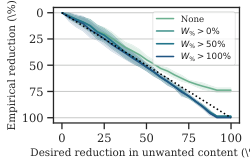

00_beta_ndcg.pdf


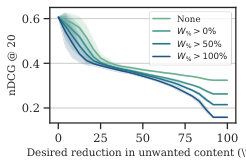

00_beta_recall.pdf


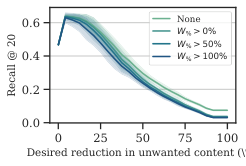

00_beta_replacement.pdf


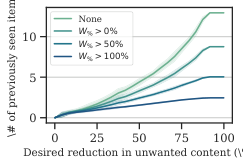

00_beta_size.pdf


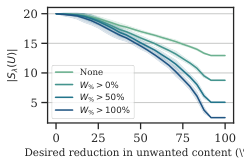

00_harm.pdf


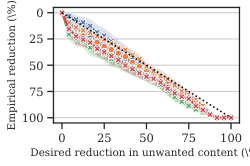

00_ndcg.pdf


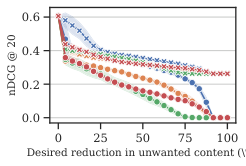

00_recall.pdf


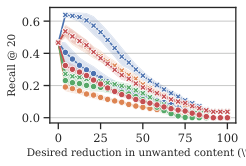

00_replacement.pdf


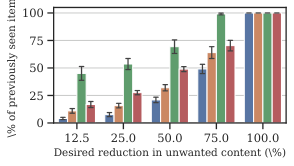

00_size.pdf


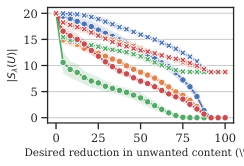

00_users_harm.pdf


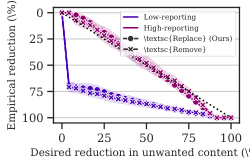

00_users_ndcg.pdf


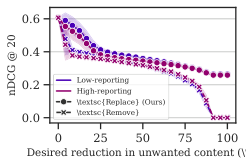

legend_only.pdf


In [11]:
assert all(n in globals() for n in ('make_figures', 'show_pdfs')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
pdfs_B = make_figures(REPO_AUTHORS, REPO_AUTHORS / "results", DIRS["figures_authors_csv"])
show_pdfs(pdfs_B)

## Parte C — Rivalutazione conformal sui punteggi pre-calcolati degli autori (solo CPU)
`ranker_kuairand.py` legge (i) i **pickle dei punteggi** (inclusi nel repo) e (ii) gli **split** `methods/kuairand/training/*.txt`.
Gli split **non sono nel repo** (`*.txt` è in `.gitignore`) e il README non lo dice: vanno rigenerati con `train_rec.py --build-only-dataset`
(deterministico: `train_test_split(..., random_state=run_id)`).

Poi si lanciano gli script ufficiali `experiments/*.sh` così come sono (16 comandi × 10 run) e si confrontano i CSV con quelli pubblicati in `results/`.
Se gli ingressi sono gli stessi ci si aspetta risultati **identici**: è una prova di riproducibilità della fase di valutazione, che è il cuore del contributo del paper (il controllo del rischio conformal).
Ogni comando stampa la propria durata (misurata e salvata: serve a riservare il tempo della valutazione finale in Parte D); la cella è **riprendibile** (i CSV già presenti vengono saltati).

In [12]:
assert all(n in globals() for n in ('sh', 'PY', 'REPO_AUTHORS')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
# C1) Rigenera gli split (stesso comando e stessi parametri degli autori, flag --build-only-dataset)
sh(f"{PY} train_rec.py --model ncf --epochs {EPOCHS} --runs {RUNS} --build-only-dataset", cwd=REPO_AUTHORS / "methods")
n_split = len(glob.glob(str(REPO_AUTHORS / "methods/kuairand/training/*.txt")))
print("File di split:", n_split, "(attesi 20 = 10 train + 10 test_calibration)")
assert n_split == 20

$ /usr/bin/python3 train_rec.py --model ncf --epochs 100 --runs 10 --build-only-dataset
[*] Finished parsing the data
Training data:  2427089
Test+Calibration data:  1040181
Training data:  2427089
Test+Calibration data:  1040181
Training data:  2427089
Test+Calibration data:  1040181
Training data:  2427089
Test+Calibration data:  1040181
Training data:  2427089
Test+Calibration data:  1040181
Training data:  2427089
Test+Calibration data:  1040181
Training data:  2427089
Test+Calibration data:  1040181
Training data:  2427089
Test+Calibration data:  1040181
Training data:  2427089
Test+Calibration data:  1040181
Training data:  2427089
Test+Calibration data:  1040181

File di split: 20 (attesi 20 = 10 train + 10 test_calibration)


In [13]:
assert all(n in globals() for n in ('run_eval_scripts', 'DIRS', 'REPO_AUTHORS', 'D', 'CORES')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
# C2) Valutazione conformal (script ufficiali). Riprendibile: i CSV gia' presenti vengono saltati.
t0 = time.time()
secs = run_eval_scripts(REPO_AUTHORS, DIRS["eval_on_authors"], available_models=None)
print(f"Parte C2 completata in {(time.time()-t0)/60:.1f} min")
if secs > 0:
    (D / "timing_eval.json").write_text(json.dumps({"eval_seconds": secs, "cores": CORES}))

[skip] 01_results_remove_replace/results_kuairand_hybrid_sigformer_harm_10_0.0_0.3_100_False_all.csv (gia' presente)
[skip] 01_results_remove_replace/results_kuairand_hybrid_gformer_harm_10_0.0_0.3_100_False_all.csv (gia' presente)
[skip] 01_results_remove_replace/results_kuairand_hybrid_siren_harm_10_0.0_0.3_100_False_all.csv (gia' presente)
[skip] 01_results_remove_replace/results_kuairand_hybrid_lightgcl_harm_10_0.0_0.3_100_False_all.csv (gia' presente)
[skip] 01_results_remove_replace/results_kuairand_remove_sigformer_harm_10_0.0_0.3_100_False_all.csv (gia' presente)
[skip] 01_results_remove_replace/results_kuairand_remove_gformer_harm_10_0.0_0.3_100_False_all.csv (gia' presente)
[skip] 01_results_remove_replace/results_kuairand_remove_siren_harm_10_0.0_0.3_100_False_all.csv (gia' presente)
[skip] 01_results_remove_replace/results_kuairand_remove_lightgcl_harm_10_0.0_0.3_100_False_all.csv (gia' presente)
[skip] 02_ablation_beta/results_kuairand_hybrid_lightgcl_harm_10_-1.0_0.3_100_

In [14]:
assert all(n in globals() for n in ('compare_exact', 'DIRS', 'REPO_AUTHORS', 'D', 'paired_report', 'where_differs')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
# C3) Confronto numerico con i CSV pubblicati dagli autori
cmp_C = compare_exact(DIRS["eval_on_authors"], REPO_AUTHORS / "results")
pd.set_option("display.width", 250, "display.max_colwidth", 90)
display(cmp_C)
cmp_C.to_csv(D / "confronto_C_valutazione_su_pickle_autori.csv", index=False)
print(cmp_C.status.value_counts().to_string())

# Dove e di quanto differiscono i file non identici (riga per riga: run x alpha)
pr = paired_report(DIRS["eval_on_authors"], REPO_AUTHORS / "results")
pr.to_csv(D / "confronto_C_differenze_per_metrica.csv", index=False)
diff_rows = pr[pr.righe_diverse != 0]
if len(diff_rows):
    print("\nFile/metriche con differenze (righe = run x alpha; media_rel_pct = differenza relativa media):")
    display(diff_rows.round({"max_abs": 8, "media_rel_pct": 4}))
    rm = [r for r in sorted((REPO_AUTHORS / "results").rglob("*remove*.csv")) if (DIRS["eval_on_authors"] / r.parent.name / r.name).exists()
          and not diff_rows[diff_rows.file == r.name].empty]
    if rm:   # 'remove' e' deterministico: una differenza qui NON puo' venire dal numero di worker
        print("\nDifferenza residua in un file 'remove' (deterministico):", rm[0].name)
        display(where_differs(DIRS["eval_on_authors"] / rm[0].parent.name / rm[0].name, rm[0]))

,file,status,maxdiff nDCG @ k,"maxdiff H(S,X)",maxdiff |S|,maxdiff random_items,maxdiff Recall @ k
0,results_kuairand_hybrid_gformer_harm_10_0.0_0.3_100_False_all.csv,DIFFERENTE,0.002742,0.000000,0.000000,0.000198,0.001323
1,results_kuairand_hybrid_lightgcl_harm_10_0.0_0.3_100_False_all.csv,DIFFERENTE,0.011647,0.000020,0.034960,0.033774,0.003846
2,results_kuairand_hybrid_sigformer_harm_10_0.0_0.3_100_False_all.csv,DIFFERENTE,0.002306,0.000000,0.000000,0.000198,0.000940
3,results_kuairand_hybrid_siren_harm_10_0.0_0.3_100_False_all.csv,DIFFERENTE,0.002755,0.000000,0.000000,0.000592,0.000739
4,results_kuairand_remove_gformer_harm_10_0.0_0.3_100_False_all.csv,QUASI IDENTICO (<1e-4),0.000004,0.000000,0.000000,0.000000,0.000010
5,results_kuairand_remove_lightgcl_harm_10_0.0_0.3_100_False_all.csv,QUASI IDENTICO (<1e-4),0.000004,0.000000,0.000000,0.000000,0.000010
6,results_kuairand_remove_sigformer_harm_10_0.0_0.3_100_False_all.csv,QUASI IDENTICO (<1e-4),0.000004,0.000000,0.000000,0.000000,0.000010
7,results_kuairand_remove_siren_harm_10_0.0_0.3_100_False_all.csv,QUASI IDENTICO (<1e-4),0.000004,0.000000,0.000000,0.000000,0.000010
8,results_kuairand_hybrid_lightgcl_harm_10_-1.0_0.3_100_False_all.csv,DIFFERENTE,0.012659,0.000099,0.143534,0.160711,0.016096
9,results_kuairand_hybrid_lightgcl_harm_10_0.0_0.3_100_False_all.csv,DIFFERENTE,0.011647,0.000020,0.034960,0.033774,0.003846


status
DIFFERENTE                                              10
QUASI IDENTICO (<1e-4)                                   6
NON RIGENERATO (non previsto dagli script ufficiali)     2

File/metriche con differenze (righe = run x alpha; media_rel_pct = differenza relativa media):


,file,metrica,righe,righe_diverse,max_abs,media_rel_pct
0,results_kuairand_hybrid_gformer_harm_10_0.0_0.3_100_False_all.csv,nDCG @ k,260,250,0.002742,0.2325
3,results_kuairand_hybrid_gformer_harm_10_0.0_0.3_100_False_all.csv,random_items,260,1,0.000198,0.0001
4,results_kuairand_hybrid_gformer_harm_10_0.0_0.3_100_False_all.csv,Recall @ k,260,250,0.001323,0.1920
5,results_kuairand_hybrid_lightgcl_harm_10_0.0_0.3_100_False_all.csv,nDCG @ k,260,243,0.011647,0.2221
6,results_kuairand_hybrid_lightgcl_harm_10_0.0_0.3_100_False_all.csv,"H(S,X)",260,3,0.000020,0.0092
7,results_kuairand_hybrid_lightgcl_harm_10_0.0_0.3_100_False_all.csv,|S|,260,3,0.034960,0.0019
8,results_kuairand_hybrid_lightgcl_harm_10_0.0_0.3_100_False_all.csv,random_items,260,52,0.033774,0.0502
9,results_kuairand_hybrid_lightgcl_harm_10_0.0_0.3_100_False_all.csv,Recall @ k,260,242,0.003846,0.1804
10,results_kuairand_hybrid_sigformer_harm_10_0.0_0.3_100_False_all.csv,nDCG @ k,260,250,0.002306,0.2222
13,results_kuairand_hybrid_sigformer_harm_10_0.0_0.3_100_False_all.csv,random_items,260,9,0.000198,0.0003



Differenza residua in un file 'remove' (deterministico): results_kuairand_remove_gformer_harm_10_0.0_0.3_100_False_all.csv


,run_id,alpha,metrica,autori,nostro,diff
17,4,0.000886,Recall @ k,0.035097,0.035087,0.00001
20,4,0.001181,Recall @ k,0.057145,0.057135,0.00001
19,4,0.001083,Recall @ k,0.057145,0.057135,0.00001
18,4,0.000984,Recall @ k,0.044601,0.044591,0.00001
21,8,0.000840,Recall @ k,0.041452,0.041462,0.00001
10,2,0.000987,Recall @ k,0.053028,0.053038,0.00001
11,2,0.001085,Recall @ k,0.053028,0.053038,0.00001
9,2,0.000888,Recall @ k,0.047563,0.047572,0.00001
16,2,0.001579,Recall @ k,0.096216,0.096226,0.00001
14,2,0.001381,Recall @ k,0.074609,0.074619,0.00001


13 figure in /content/drive/MyDrive/IR_RecSys2025_repro/figures_eval_on_authors: ['00_beta_harm.pdf', '00_beta_ndcg.pdf', '00_beta_recall.pdf', '00_beta_replacement.pdf', '00_beta_size.pdf', '00_harm.pdf', '00_ndcg.pdf', '00_recall.pdf', '00_replacement.pdf', '00_size.pdf', '00_users_harm.pdf', '00_users_ndcg.pdf', 'legend_only.pdf']
00_beta_harm.pdf


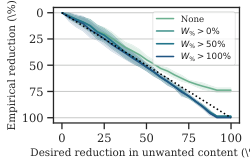

00_beta_ndcg.pdf


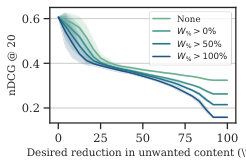

00_beta_recall.pdf


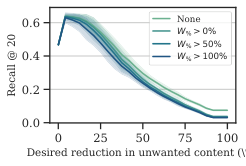

00_beta_replacement.pdf


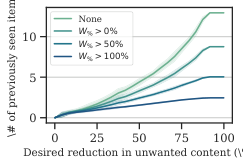

00_beta_size.pdf


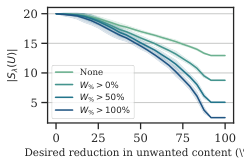

00_harm.pdf


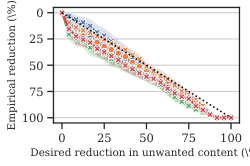

00_ndcg.pdf


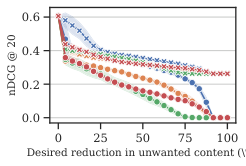

00_recall.pdf


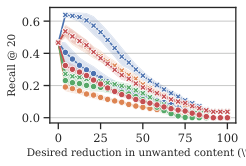

00_replacement.pdf


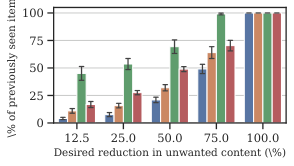

00_size.pdf


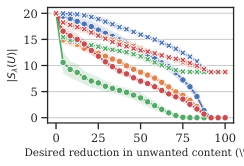

00_users_harm.pdf


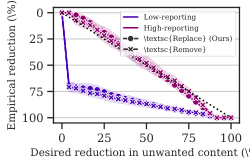

00_users_ndcg.pdf


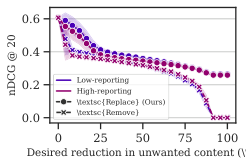

legend_only.pdf


In [15]:
assert all(n in globals() for n in ('make_figures', 'DIRS', 'REPO_AUTHORS')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
# C4) Figure da CSV rigenerati
pdfs_C = make_figures(REPO_AUTHORS, DIRS["eval_on_authors"], DIRS["figures_eval_on_authors"])
show_pdfs(pdfs_C)

### C5 — Verifica mirata: il metodo `hybrid` dipende dal numero di worker
Rilancia **solo la run 0** di `hybrid` / `sigformer` (comando di `run_experiment_replace_remove.sh`, `--runs 1`) con 8 worker e la confronta con la run 0 del CSV degli autori. Atteso: **IDENTICO**. Se in C2 esiste già un CSV prodotto con meno worker, la cella mostra anche il suo confronto sulla stessa run (atteso: differenze in nDCG e Recall, non in H, |S|, random_items). Durata: circa 7 minuti con 2 CPU.

In [16]:
assert all(n in globals() for n in ('run_logged', 'ranker_cmd', 'ensure_worker_wrapper', 'cmp_files', 'REPO_AUTHORS', 'DIRS', 'shutil')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
# C5) hybrid / sigformer, solo run 0, 8 worker, confronto con la run 0 degli autori
ensure_worker_wrapper(REPO_AUTHORS)
c5_dir = DIRS["eval_on_authors"].parent / "verifica_C5_hybrid_8_worker"; c5_dir.mkdir(parents=True, exist_ok=True)
c5_csv = c5_dir / "results_kuairand_hybrid_sigformer_harm_1_0.0_0.3_100_False_all.csv"
ref_csv = REPO_AUTHORS / "results/01_results_remove_replace/results_kuairand_hybrid_sigformer_harm_10_0.0_0.3_100_False_all.csv"
if not c5_csv.exists():
    t0 = time.time()
    run_logged(ranker_cmd("python ranker_kuairand.py --runs 1 --score-model sigformer --score-type harm --method hybrid --cores 8 --beta 0.0 --epoch 100"),
               cwd=REPO_AUTHORS, log_path=DIRS["logs"] / "verifica_C5.log", env={"PYTHONPATH": ".", "RANKER_FORCE_WORKERS": "8"}, show=None)
    shutil.move(str(REPO_AUTHORS / c5_csv.name), str(c5_csv))
    print(f"fatto in {(time.time()-t0)/60:.1f} min")
st8, d8, n8 = cmp_files(c5_csv, ref_csv, only_runs=[0])
print(f"\n8 worker  vs autori (run 0, {n8} righe): {st8}")
print("   max diff per metrica:", {k: float(f"{v:.3g}") for k, v in d8.items()})
old_csv = DIRS["eval_on_authors"] / "01_results_remove_replace" / ref_csv.name
if old_csv.exists():
    a = pd.read_csv(old_csv, float_precision="high"); a = a[a.run_id == 0]
    tmp = c5_dir / "_run0_del_C2.csv"; a.to_csv(tmp, index=False)
    stN, dN, nN = cmp_files(tmp, ref_csv, only_runs=[0])
    print(f"CSV di C2 (run 0) vs autori ({nN} righe): {stN}")
    print("   max diff per metrica:", {k: float(f"{v:.3g}") for k, v in dN.items()})
    tmp.unlink()

fatto in 19.2 min

8 worker  vs autori (run 0, 26 righe): IDENTICO
   max diff per metrica: {'nDCG @ k': 0.0, 'H(S,X)': 0.0, '|S|': 0.0, 'random_items': 0.0, 'Recall @ k': 0.0}
CSV di C2 (run 0) vs autori (26 righe): DIFFERENTE
   max diff per metrica: {'nDCG @ k': 0.00156, 'H(S,X)': 0.0, '|S|': 0.0, 'random_items': 0.0, 'Recall @ k': 0.000651}


## Riepilogo e cosa portare al professore

In [17]:
assert all(n in globals() for n in ('D', 'DIRS')), "Mancano variabili delle celle precedenti (runtime riavviato o celle saltate): usa Runtime > Esegui tutto, oppure riesegui le celle dall'alto."
print("== Stato output:", D)
for k, v in DIRS.items():
    n = sum(1 for _ in v.rglob("*") if _.is_file())
    print(f"  {k:26s} {n:4d} file")
if "status_table" in globals():
    print(); display(status_table())
print("\nParte C (valutazione su pickle degli autori):")
print(cmp_C.status.value_counts().to_string() if "cmp_C" in globals() else "  non ancora eseguita")

== Stato output: /content/drive/MyDrive/IR_RecSys2025_repro
  retrain_pickles               0 file
  eval_on_authors              16 file
  eval_on_retrained             0 file
  figures_authors_csv          13 file
  figures_eval_on_authors      13 file
  figures_retrained             0 file
  logs                          4 file
  patches                       1 file

Parte C (valutazione su pickle degli autori):
status
DIFFERENTE                                              10
QUASI IDENTICO (<1e-4)                                   6
NON RIGENERATO (non previsto dagli script ufficiali)     2


### Osservazioni di riproducibilità emerse (da riportare nel report / all'autore)
1. `requirement.txt` (nome al singolare) **non elenca `torchsparsegradutils`**, importata da `methods/SIGformer/model.py`; poiché `train_rec.py` importa tutti i modelli all'avvio, senza di essa nessun training parte.
2. Gli **split** (`methods/kuairand/training/*.txt`) non sono nel repo (`.gitignore: *.txt`), ma `ranker_kuairand.py` li richiede: la sola sezione *Run again all the evaluations* del README non basta; serve `train_rec.py --build-only-dataset`.
3. I comandi di plotting del README non impostano `PYTHONPATH`, ma `plot_figure_5.py` e `plot_figure_6.py` fanno `from analytics...`.
4. Gli script usano `include_groups=True` in `groupby.apply`: **incompatibile con pandas ≥ 3**.
5. Incoerenza fra README e `methods/run_all.sh` sui batch size (e `lightgcl 2014` nel README); `ncfharm` è in `run_all.sh` ma non nel README né usato da `experiments/*.sh`.
6. Gli script `experiments/run_ablation_beta.sh` rigenerano 4 valori di β (−1, 0, 0.5, 1) mentre `results/02_ablation_beta/` ne contiene 6 (anche 0.1 e 1.5): quei due CSV non sono riproducibili con gli script forniti.
7. `methods/LightGCL/model.py` chiama `.cuda(...)` in modo fisso: il training di LightGCL richiede una GPU NVIDIA.
8. La griglia di `alpha` nei CSV dipende dallo split (non è uguale fra le run): per confrontare celle fra run serve normalizzare per `alpha_max` della run (come fa lo script di plotting con `rescale_group`).
9. **I risultati del metodo `hybrid` dipendono dal numero di processi worker**, quindi dalla macchina. `ranker_kuairand.py` fissa `np.random.seed(42)` una sola volta nel processo principale e poi usa un `ProcessPoolExecutor` con `min(--cores, os.cpu_count())` worker; con `fork` ogni worker eredita lo stesso stato del generatore e, nel blocco di utenti che gli tocca, estrae gli oggetti sostitutivi con `np.random.choice` (`src/score_functions.py`, righe 67 e 70). Cambiando il numero di blocchi cambia quale estrazione riceve ogni utente (e anche la calibrazione di γ, che usa le stesse estrazioni). Il metodo `remove` non estrae nulla e non dipende dal numero di worker. Verifica fatta: run 0, `hybrid`/`sigformer`, 8 worker (come `--cores 8` degli script) → CSV identico a quello degli autori (26 righe, 5 metriche su 5); 2 worker → nDCG fino a 1.6e-3 e Recall fino a 6.5e-4 di differenza, con H(S,X), |S| e random_items identici. Conseguenza pratica: chi esegue `experiments/*.sh` su una macchina con meno di 8 CPU ottiene numeri diversi (stessa procedura, estrazioni casuali diverse; l'entità va misurata, vedi `paired_report` in C3) senza alcun avviso.